# 11 — Centroid + MMR passo per passo (versione didattica)

Questo notebook segue **una sola riga** di Multi-News (un cluster di 2-3 articoli + il riassunto
umano di riferimento) e mostra, un passaggio alla volta, come **Centroid-based (MEAD) + MMR**
(Radev et al., 2000; Carbonell & Goldstein, 1998) trasforma il testo in un riassunto estrattivo e come lo si valuta.

A differenza di [`notebooks/11_centroid_mmr.ipynb`](../notebooks/11_centroid_mmr.ipynb),
che gira in batch su migliaia di righe e salva solo i risultati, qui l'obiettivo è **capire**:
ogni passaggio è spiegato, calcolato "a mano" quando possibile e **verificato contro l'implementazione
del benchmark** (le `assert` garantiscono che quello che vedi qui sia esattamente ciò che fa il codice
di produzione).

## Il workflow in una figura

```
documento (2-3 articoli)
      │  1. scelta della riga
      ▼
frasi  s₀ s₁ … s_{N-1}            ← 2. suddivisione in frasi
      │
      ▼
vettori delle frasi                 ← 3. TF-IDF (o embedding BERT)
      │
      ├──► centroide = media dei vettori      ← 4. il "contenuto medio" del cluster
      │         │
      │         ▼
      │    rilevanza(i) = coseno(frase i, centroide)    ← 5. quanto una frase è centrale
      │
      ▼
matrice di similarità N×N           ← 6. coseno tra tutte le coppie (serve a misurare la ridondanza)
      │
      ▼
selezione greedy MMR                ← 7. λ·rilevanza − (1−λ)·max similarità con le già scelte
      │
      ▼
riassunto estrattivo                ← 8-9. selezione + generazione (frasi in ordine di documento)
      │
      ▼
confronto con il riferimento        ← 10. + variante a budget di parole
      │
      ▼
ROUGE / BLEU / METEOR               ← 11. metriche
      │
      ▼
interpretazione                     ← 12-13.
```

## L'idea in due righe
Una frase è **importante** se è **vicina al contenuto medio del cluster** (il *centroide*: le
informazioni ripetute da più articoli pesano di più nella media) **e** non ripete ciò che il riassunto
già dice. La prima condizione è la *rilevanza*, la seconda la *novità*: MMR le combina in un unico
punteggio

> score(frase) = **λ · S(frase, centroide)** − **(1 − λ) · max** *R*(frase, frasi già scelte)

e sceglie le frasi **una alla volta** (selezione *greedy*). Con `λ = 1` la ridondanza viene ignorata
(puro centroide); con `λ` più bassa le frasi simili a quelle già scelte vengono penalizzate. Il
benchmark usa `λ = 0,7`.

> È l'unico metodo del benchmark con un **controllo esplicito della ridondanza** tra le fonti.
> TextRank/LexRank ([`01`](01_textrank_didattico.ipynb), [`02`](02_lexrank_didattico.ipynb)) non ce l'hanno: qui
> non c'è PageRank né grafo, ma un centroide e un greedy. I passi 1-2 e 10-12 sono identici agli altri notebook didattici.

⚠️ **Una riga non è un benchmark.** Le metriche della sezione 11 riguardano un solo esempio e
servono a capire *come si calcolano*, non a stabilire quale metodo sia migliore (per questo
esistono i notebook di benchmark su 5.610 righe).

## 0. Preparazione
Importiamo le librerie e le funzioni condivise del progetto (`summ_utils`). Il notebook si può
lanciare dalla cartella `notebooks_didattici/` o dalla radice del repository.

In [1]:
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.metrics.pairwise import cosine_similarity

# radice del progetto: la cartella sopra notebooks_didattici/ (o la cwd se già alla radice)
_cwd = Path.cwd()
BASE = _cwd.parent if _cwd.name in ('notebooks_didattici', 'notebooks') else _cwd
sys.path.insert(0, str(BASE / 'notebooks'))

import summ_utils as su
from pyAutoSummarizer.base import psr

su.stile_grafici()
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 110

P = su.percorsi_standard(BASE)
print('Radice del progetto:', BASE)

C:\Users\maccu\AppData\Roaming\Python\Python312\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.6.0)/charset_normalizer (3.4.7) doesn't match a supported version!
  warnings.warn(


C:\Users\maccu\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Radice del progetto: C:\Users\maccu\OneDrive\Desktop\Master_Project


## 1. Selezione del testo di partenza
Multi-News è composto da *cluster*: ogni riga contiene **2-3 articoli** sullo stesso evento,
concatenati con il separatore `|||||`, e un **riassunto scritto da un umano** (il
*riferimento*, o *gold*). Lavoriamo sulla **split di test** (la stessa su cui il benchmark
valuta i metodi).

`ROW_ID` è l'indice globale della riga in `data/tab/complete.tab`. La riga predefinita
(**50492**) è stata scelta perché è breve (19 frasi): la matrice di similarità e i grafici
restano **leggibili**. Puoi cambiare `ROW_ID` con qualunque altra riga della split di test
(50491-56100): il resto del notebook si adatta (con documenti molto lunghi i grafici
diventano però fitti).

**`MODALITA`** sceglie come viene fissata la **lunghezza** del riassunto. Centroid+MMR produce un
*ordine di selezione* (la sequenza del greedy): quante frasi prenderne è una scelta esterna.

| `MODALITA` | regola | corrisponde a |
|---|---|---|
| `'frasi'` | le prime `N_SENTENCES` (= 11) frasi scelte dal greedy | ambito `test` del benchmark |
| `'budget'` | frasi nell'ordine del greedy finché si raggiunge la lunghezza in parole del riferimento, poi tetto a 1,25× | ambito `test_budgetref` (issue #16) |

Cambiando `MODALITA` le sezioni 8-12 si adattano; le due alternative restano comunque
confrontabili nelle tabelle delle sezioni 10 e 11.

`LAMBDA` è il peso di MMR (0,7 nel benchmark). **`VETTORIZZAZIONE`** sceglie come si rappresentano le
frasi: `'tfidf'` (variante `centroid_mmr`, default) oppure `'bert'` (variante `centroid_mmr_bert`,
embedding MiniLM come TextRank). La logica è identica, cambia solo lo spazio dei vettori; la sezione 13
le confronta entrambe sulla stessa riga.

In [2]:
ROW_ID = 50492          # riga della split di test (50491-56100)
# Come si decide la LUNGHEZZA del riassunto (MMR produce solo un ordine di selezione):
#   'frasi'  -> le prime N_SENTENCES frasi scelte (benchmark ambito `test`)
#   'budget' -> frasi nell'ordine del greedy fino alla lunghezza in parole del riferimento,
#               poi tetto a 1,25x (benchmark ambito `test_budgetref`, issue #16)
MODALITA = 'budget'
N_SENTENCES = 11           # usato se MODALITA == 'frasi' (mediana del corpus)
LAMBDA = 0.7               # peso MMR: rilevanza (centroide) vs novità (anti-ridondanza)
VETTORIZZAZIONE = 'tfidf'  # 'tfidf' (centroid_mmr) | 'bert' (centroid_mmr_bert)
K_ORDINE_BUDGET = 50       # lunghezza massima dell'ordine del greedy in modalità 'budget' (come il benchmark)
ST_MODEL = 'all-MiniLM-L6-v2'
assert MODALITA in ('frasi', 'budget'), "MODALITA deve essere 'frasi' oppure 'budget'"
assert VETTORIZZAZIONE in ('tfidf', 'bert'), "VETTORIZZAZIONE deve essere 'tfidf' oppure 'bert'"

import csv

PRIMO_ROW_ID_TEST = 50491          # le righe di test sono 50491-56100 in complete.tab
PERCORSO_TEST = P['complete_tab'].with_name('test.tab')   # solo split test (68 MB): basta e avanza

def carica_riga_test(row_id):
    '''Legge UNA riga di test. Prima da data/tab/test.tab (leggero, ideale su Colab: row_id = 50491 + indice,
    allineamento verificato con complete.tab), altrimenti da complete.tab (690 MB).'''
    problemi = []
    if PERCORSO_TEST.exists():
        try:
            with open(PERCORSO_TEST, encoding='utf-8', newline='') as f:
                lettore = csv.reader(f, delimiter='\t')
                for _ in range(su.HEADER_LINES_TAB):
                    next(lettore)
                for i, riga in enumerate(lettore):
                    if i == row_id - PRIMO_ROW_ID_TEST:
                        documento, riassunto_umano = riga          # ValueError se la riga è corrotta
                        return {'row_id': row_id, 'split': 'test', 'document': documento, 'summary': riassunto_umano}
            problemi.append(f'{PERCORSO_TEST.name}: row_id {row_id} fuori dalla split di test (50491-56100)')
        except ValueError:
            problemi.append(f'{PERCORSO_TEST.name} è incompleto o corrotto (riga con un numero di colonne inatteso)')
    else:
        problemi.append(f'{PERCORSO_TEST} non trovato')
    if P['complete_tab'].exists():
        try:
            return next(es for es in su.itera_split(P['complete_tab'], 'test') if es['row_id'] == row_id)
        except (ValueError, StopIteration):
            problemi.append(f'{P["complete_tab"].name} è incompleto o corrotto')
    else:
        problemi.append(f'{P["complete_tab"]} non trovato')
    raise RuntimeError('Impossibile leggere la riga: ' + ' | '.join(problemi) + '.\n'
        'I file .tab del repository sono su Git LFS: un `git clone` senza LFS (o un upload interrotto su Colab) '
        'dà un puntatore di pochi byte o un file troncato. Soluzioni: `git lfs pull`, oppure carica '
        'data/tab/test.tab (68 MB) in <radice>/data/tab/.')

esempio = carica_riga_test(ROW_ID)

articoli = [a.strip() for a in esempio['document'].split('|||||')]
riferimento = su.pulisci_riferimento(esempio['summary'])

print(f"row_id {ROW_ID} | split: {esempio['split']} | articoli nel cluster: {len(articoli)}")
print(f"parole nel documento: {len(esempio['document'].split())} | parole nel riferimento: {len(riferimento.split())}")
for k, a in enumerate(articoli, 1):
    print(f"\n--- Articolo {k} ({len(a.split())} parole) ---")
    print(textwrap.fill(a[:500] + ' […]', 110))
print('\n=== RIASSUNTO DI RIFERIMENTO (umano) ===')
print(textwrap.fill(riferimento, 110))

row_id 50492 | split: test | articoli nel cluster: 2
parole nel documento: 664 | parole nel riferimento: 168

--- Articolo 1 (482 parole) ---
UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, became an accidental spokesperson
for gay rights overnight on Boing Boing     It’s time to clarify a few details about the controversial “Hey
Facebook what’s SO wrong with a pic of two men kissing?” story, as it now beginning to be reported in the
mainstream media, and not always correctly.     First of all, with regards to the picture:     The photo which
was used to illustrate my first post about the John Snow Kiss-In i […]

--- Articolo 2 (181 parole) ---
|| News ||     Page 1 of 1             UPDATED: A photo of two men kissing that was posted on a Facebook page
protesting a London pub’s decision to eject a same-sex couple for kissing has been removed by the social
networking site, an error, according to a rep for the company.         "The photo in question does not vi

**Cosa abbiamo visto.** Il documento è l'unione dei 2-3 articoli; il riferimento è molto più
breve ed è scritto in modo *astratto* (riformula), mentre Centroid+MMR può solo
**copiare frasi intere** dal documento: per questo è *estrattivo*.

## 2. Suddivisione del testo in frasi
L'unità di analisi è la **frase**: ogni frase è un candidato del riassunto. Passi, uguali a quelli
del benchmark (`segmenta()` del notebook 11):

1. il separatore `|||||` tra articoli viene sostituito da un a capo (`su.prepara_documento`),
   altrimenti resterebbe dentro le "frasi";
2. `psr.summarization(...)` spezza il testo con una **espressione regolare**: taglia dopo
   `. ! ?` seguiti da spazio, **tranne** dopo abbreviazioni (`Mr`, `Dr`, `Prof`, `St`, mesi
   abbreviati, iniziali maiuscole come in "J. Smith");
3. si tengono le frasi **originali** (`s.original`, in ordine di documento) e si scartano le stringhe vuote.

**Differenza rispetto a TextRank/LexRank:** qui *non* si usa `s.corpus` (il testo pre-processato
dalla libreria). Il pre-processing, se serve, lo fa il vettorizzatore stesso (sezione 3): la
segmentazione è l'unica cosa che si prende da `pyAutoSummarizer`.

In [3]:
documento = su.prepara_documento(esempio['document'])
s = psr.summarization(documento, stop_words=['en'])

# identico a segmenta() del notebook 11
frasi = [f.strip() for f in getattr(s, 'original', []) if f and f.strip()]
N = len(frasi)
print(f'Il documento è stato diviso in N = {N} frasi (⇒ {N*(N-1)//2} coppie di frasi distinte).\n')

tab_frasi = pd.DataFrame({'frase': range(N), 'parole': [len(f.split()) for f in frasi],
                          'testo': [f[:105] + ('…' if len(f) > 105 else '') for f in frasi]}).set_index('frase')
display(tab_frasi)

Il documento è stato diviso in N = 19 frasi (⇒ 171 coppie di frasi distinte).



,parole,testo
frase,,
0,60,"UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, became an accidental spokesper…"
1,59,"First of all, with regards to the picture: \n \n The photo which was used to illustrate my first post about…"
2,23,I am not a regular viewer so I can’t say if the man on the right is an extra or an actual character
3,33,"This picture has itself caused scandal in the UK, as it was a gay kiss that was broadcast before the wate…"
4,21,"However, since this episode aired (October 2008) Christian now has a boyfriend and a few more gay kisses …"
5,25,"In relation to the John Snow Kiss-In event, I used this particular photo because I considered it to be qu…"
6,15,The photos I had considered using before I chose that one are much more racy
7,3,Oh the irony
8,37,"Secondly, the removal of the Facebook John Snow Kiss-In event: \n \n It turns out that the Facebook event f…"


**Cosa abbiamo visto.** Le frasi hanno lunghezze molto diverse e sono numerate `0 … N-1` nell'ordine
in cui compaiono nel documento: questi numeri sono gli **indici** che useremo in tutti i
grafici. Nota anche che la divisione è *euristica*: titoli, didascalie o frasi senza punto finale
possono diventare "frasi" a sé.

## 3. Vettori delle frasi
Per calcolare un "contenuto medio" e delle distanze serve rappresentare ogni frase con un **vettore**.
Il benchmark ne prova due, con la stessa logica a valle:

- **TF-IDF** (`centroid_mmr`): vettore sparso di pesi lessicali, costruito *solo* sulle frasi del
  documento corrente (nessun modello pre-addestrato). `TfidfVectorizer(stop_words='english')` di
  scikit-learn fa da sé minuscole, tokenizzazione e rimozione delle stopword inglesi.
  `idf(t) = ln((1 + N) / (1 + df(t))) + 1`, con `df(t)` = numero di frasi che contengono `t`;
  peso = `tf × idf`; ogni vettore è poi **normalizzato a norma 1** (L2).
- **BERT** (`centroid_mmr_bert`): embedding denso `all-MiniLM-L6-v2` (384 dimensioni),
  anch'esso normalizzato L2. Cattura la vicinanza di *significato* anche senza parole in comune.

Poiché i vettori hanno **norma 1**, il prodotto scalare di due vettori è già il loro coseno.
Nella sezione 13 vedremo anche la variante BERT; ora seguiamo quella scelta da `VETTORIZZAZIONE`.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

def vettorizza_tfidf(frasi):
    '''Matrice TF-IDF sparsa (n, vocab), righe L2-normalizzate (identica al notebook 11).'''
    return TfidfVectorizer(stop_words='english').fit_transform(frasi)

_bert = {}
def vettorizza_bert(frasi):
    '''Embedding Sentence-BERT densi (n, dim), L2-normalizzati. Modello caricato una volta sola.'''
    if 'model' not in _bert:
        from sentence_transformers import SentenceTransformer
        _bert['model'] = SentenceTransformer(ST_MODEL, device=su.rileva_device())
    return _bert['model'].encode(frasi, normalize_embeddings=True, show_progress_bar=False)

VETTORIZZATORI = {'tfidf': vettorizza_tfidf, 'bert': vettorizza_bert}

X = VETTORIZZATORI[VETTORIZZAZIONE](frasi)
Xd = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)          # versione densa per i calcoli a mano

print(f'Vettorizzazione: {VETTORIZZAZIONE} | forma della matrice: {Xd.shape} (N frasi × dimensione)')
print(f'Norma di ogni vettore: min {np.linalg.norm(Xd, axis=1).min():.3f}, max {np.linalg.norm(Xd, axis=1).max():.3f}  → tutti a 1')
if VETTORIZZAZIONE == 'tfidf':
    vett = TfidfVectorizer(stop_words='english').fit(frasi)
    vocabolario = vett.get_feature_names_out()
    print(f'Vocabolario: {len(vocabolario)} termini | celle diverse da zero: {(Xd > 0).mean():.1%}  → matrice sparsa')

    # verifica a mano dell'IDF per un termine: il primo termine con peso maggiore nella frase 0
    j = int(np.argmax(Xd[0])); t = vocabolario[j]
    df_t = int((Xd[:, j] > 0).sum())
    idf_manuale = np.log((1 + N) / (1 + df_t)) + 1
    print(f"termine '{t}': compare in {df_t} frasi su {N}  →  idf = ln((1+{N})/(1+{df_t})) + 1 = {idf_manuale:.4f}")
    assert np.isclose(idf_manuale, vett.idf_[j])
    print(f'idf di scikit-learn: {vett.idf_[j]:.4f}  ✔')

    def top_termini(i, k=6):
        idx = np.argsort(Xd[i])[::-1][:k]
        return ', '.join(f'{vocabolario[j]} ({Xd[i, j]:.2f})' for j in idx if Xd[i, j] > 0)
    display(pd.DataFrame({'frase': range(4), 'termini con peso maggiore': [top_termini(i) for i in range(4)]}).set_index('frase'))

Vettorizzazione: tfidf | forma della matrice: (19, 207) (N frasi × dimensione)
Norma di ogni vettore: min 1.000, max 1.000  → tutti a 1
Vocabolario: 207 termini | celle diverse da zero: 7.5%  → matrice sparsa
termine 'boing': compare in 1 frasi su 19  →  idf = ln((1+19)/(1+1)) + 1 = 3.3026
idf di scikit-learn: 3.3026  ✔


,termini con peso maggiore
frase,
0,"boing (0.36), update (0.18), wrong (0.18), read (0.18), spokesperson (0.18), story (0.18)"
1,"john (0.30), played (0.21), promotional (0.21), regards (0.21), british (0.21), characters (0.21)"
2,"viewer (0.36), right (0.36), say (0.36), regular (0.36), character (0.36), extra (0.36)"
3,"watershed (0.31), uk (0.31), scandal (0.31), complaints (0.31), bbc (0.31), led (0.31)"


**Cosa abbiamo visto.** Con TF-IDF due frasi saranno simili se **condividono termini rari e
caratteristici**: si misura la sovrapposizione *lessicale*, non il significato. Frasi che dicono la
stessa cosa con parole diverse risultano poco simili — è il limite che gli embedding BERT cercano di
superare (sezione 13).

## 4. Il centroide
Il **centroide** è il vettore **medio** di tutte le frasi del cluster:

`c = (1/N) · Σᵢ xᵢ`

È l'idea del sistema *MEAD* (Radev et al., 2000): se più articoli parlano della stessa cosa, i
termini corrispondenti compaiono in molte frasi e hanno quindi **peso alto nella media**. Il centroide
è dunque un "riassunto implicito" del cluster nello spazio dei vettori.

Attenzione a due cose:

- il centroide è **uno solo** per cluster (non è un clustering a più centroidi come k-means);
- la media di vettori normalizzati ha in generale **norma < 1** (i vettori puntano in direzioni diverse e si
  compensano in parte). Non è un problema: nel coseno la norma si semplifica.

In [5]:
centroide = Xd.mean(axis=0, keepdims=True)                            # (1, dim): la media delle righe di X
print(f'Forma del centroide: {centroide.shape} | norma = {np.linalg.norm(centroide):.3f} (< 1: i vettori non puntano tutti nello stesso verso)')
assert centroide.shape == (1, Xd.shape[1])
assert np.allclose(centroide, np.asarray(X.mean(axis=0)).reshape(1, -1))   # come analizza_mmr() del benchmark

if VETTORIZZAZIONE == 'tfidf':
    top = np.argsort(centroide[0])[::-1][:12]
    print('\nTermini con peso maggiore nel centroide (il "tema medio" del cluster):')
    print(', '.join(f'{vocabolario[j]} ({centroide[0, j]:.3f})' for j in top))

Forma del centroide: (1, 207) | norma = 0.309 (< 1: i vettori non puntano tutti nello stesso verso)

Termini con peso maggiore nel centroide (il "tema medio" del cluster):
event (0.091), facebook (0.069), kiss (0.065), photo (0.064), page (0.062), john (0.054), people (0.049), kissing (0.048), snow (0.046), post (0.045), removed (0.044), used (0.044)


**Cosa abbiamo visto.** I termini col peso più alto nel centroide sono quelli che ricorrono in molte
frasi (nomi, luoghi, parole-chiave dell'evento): è il "tema" attorno a cui le frasi del cluster si
raccolgono. Le frasi che contengono questi termini saranno le più rilevanti.

## 5. Rilevanza di ogni frase
La **rilevanza** di una frase è la sua *cosine similarity* con il centroide:

`S(i, c) = cos(xᵢ, c) = xᵢ · c / (‖xᵢ‖ ‖c‖)`

Vale tra 0 (nessun termine in comune col tema del cluster) e 1 (stessa direzione del centroide).
Calcoliamola a mano e verifichiamola contro `cosine_similarity` di scikit-learn.

✔ Rilevanza a mano = cosine_similarity(X, centroide)


,frase,rilevanza,parole,testo
posizione,,,,
1,8,0.450,37,"Secondly, the removal of the Facebook John Snow Kiss-In event: \n \n It turns out …"
2,17,0.448,13,The page used a photo of two men kissing to promote the event…
3,12,0.420,42,"Also, Richard did not state in his post that Facebook HAD taken the event page d…"
4,14,0.416,68,"Here is a report on the John Snow Kiss-In from the Guardian, featuring an interv…"
5,11,0.403,62,Now if Facebook will only reply to Richard’s query about why they removed my ori…
6,5,0.389,25,"In relation to the John Snow Kiss-In event, I used this particular photo because…"
7,10,0.363,61,"Before it goes too far, I just want people to know that FB have NOT removed the …"
8,18,0.351,68,"According to NYULocal.com, the photo was quickly removed and the following e-mai…"
9,1,0.341,59,"First of all, with regards to the picture: \n \n The photo which was used to illus…"


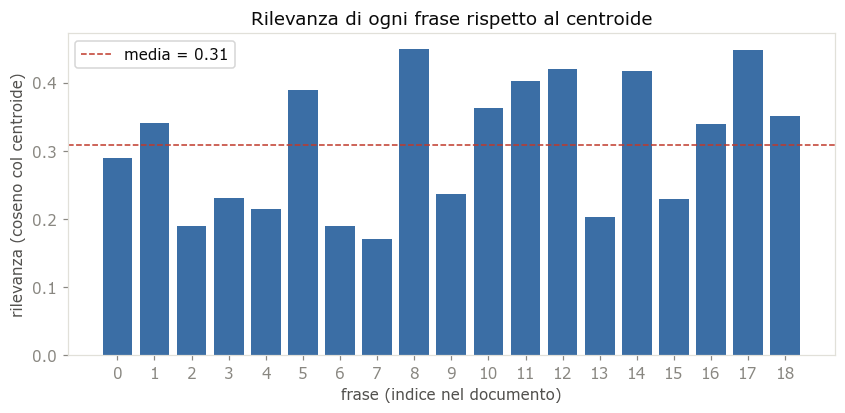

In [6]:
def coseno(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

rilevanza = cosine_similarity(Xd, centroide).ravel()               # S(frase, centroide), come nel benchmark
rilevanza_manuale = np.array([coseno(Xd[i], centroide[0]) for i in range(N)])
assert np.allclose(rilevanza, rilevanza_manuale)
print('✔ Rilevanza a mano = cosine_similarity(X, centroide)')

ord_rel = np.argsort(rilevanza)[::-1]
display(pd.DataFrame({
    'posizione': range(1, N + 1), 'frase': [int(i) for i in ord_rel],
    'rilevanza': [round(float(rilevanza[i]), 3) for i in ord_rel],
    'parole': [len(frasi[i].split()) for i in ord_rel],
    'testo': [frasi[i][:80] + '…' for i in ord_rel],
}).set_index('posizione'))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(range(N), rilevanza, color='#3b6ea5')
ax.set_xticks(range(N)); ax.set_xlabel('frase (indice nel documento)'); ax.set_ylabel('rilevanza (coseno col centroide)')
ax.axhline(rilevanza.mean(), color='#c0392b', ls='--', lw=1, label=f'media = {rilevanza.mean():.2f}')
ax.legend(); ax.set_title('Rilevanza di ogni frase rispetto al centroide')
plt.show()

**Cosa abbiamo visto.** Se ci fermassimo qui (λ = 1) il riassunto sarebbe semplicemente "le frasi con la
rilevanza più alta". Il problema: in un cluster di articoli sulla **stessa notizia**, le frasi più
rilevanti tendono a essere **quasi duplicate** (ciascun articolo racconta il fatto principale) e
verrebbero scelte tutte insieme. Serve il secondo termine di MMR.

## 6. Similarità tra le frasi (la misura della ridondanza)
Per penalizzare le frasi ripetitive serve sapere **quanto due frasi si assomigliano**: stessa
*cosine similarity*, ma tra frasi, per **tutte le coppie**. Si ottiene una matrice quadrata
**N × N** `R[i, j]` (simmetrica, diagonale = 1). Qui **non c'è** il "+0,1" di LexRank e **non c'è**
PageRank: la matrice serve solo a misurare la ridondanza.

La *heatmap* ne mostra la struttura (diagonale nascosta: è sempre 1 e schiaccerebbe la scala):
**blocchi chiari** fuori diagonale = coppie di frasi **ridondanti**, cioè ciò che MMR eviterà di
scegliere due volte.

Forma: (19, 19) | simmetrica: True | diagonale = 1
Coppie con similarità esattamente 0: 86 su 171


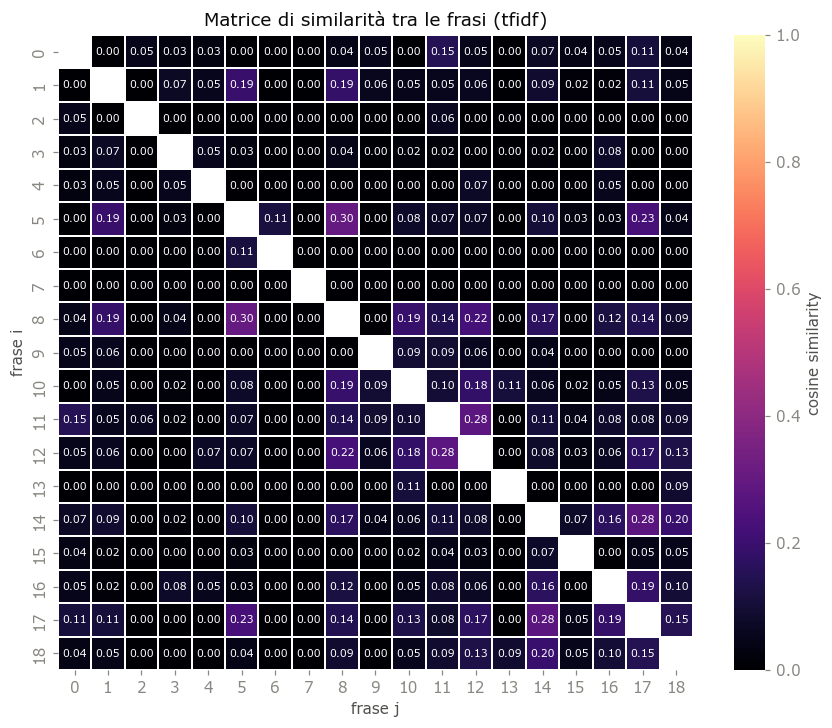

Le 3 coppie più ridondanti:
  (5, 8)  similarità 0.30
     [5] In relation to the John Snow Kiss-In event, I used this particular photo because I conside…
     [8] Secondly, the removal of the Facebook John Snow Kiss-In event: 
 
 It turns out that the F…
  (11, 12)  similarità 0.28
     [11] Now if Facebook will only reply to Richard’s query about why they removed my original post…
     [12] Also, Richard did not state in his post that Facebook HAD taken the event page down, he ju…
  (14, 17)  similarità 0.28
     [14] Here is a report on the John Snow Kiss-In from the Guardian, featuring an interview with M…
     [17] The page used a photo of two men kissing to promote the event…


In [7]:
sim = cosine_similarity(Xd)                                         # R(i, j), N x N
assert np.isclose(coseno(Xd[0], Xd[1]), sim[0, 1])
print(f'Forma: {sim.shape} | simmetrica: {np.allclose(sim, sim.T)} | diagonale = {sim.diagonal().min():.0f}')
coppie = np.triu_indices(N, 1)
print(f'Coppie con similarità esattamente 0: {(sim[coppie] == 0).sum()} su {len(coppie[0])}')

fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(sim, mask=np.eye(N, dtype=bool), annot=(N <= 22), fmt='.2f', annot_kws={'size': 7}, cmap='magma',
            vmin=0, vmax=1, square=True, linewidths=.3, linecolor='white', cbar_kws={'label': 'cosine similarity'}, ax=ax)
ax.set_xlabel('frase j'); ax.set_ylabel('frase i')
ax.set_title(f'Matrice di similarità tra le frasi ({VETTORIZZAZIONE})')
plt.show()

top_coppie = sorted(((sim[i, j], i, j) for i, j in zip(*coppie)), reverse=True)[:3]
print('Le 3 coppie più ridondanti:')
for v, i, j in top_coppie:
    print(f'  ({i}, {j})  similarità {v:.2f}\n     [{i}] {frasi[i][:90]}…\n     [{j}] {frasi[j][:90]}…')

**Cosa abbiamo visto.** Le coppie più simili sono quelle che MMR considererà "la stessa informazione":
se ne è già stata scelta una, scegliere anche l'altra aggiungerebbe poco. Il passo successivo usa
questa matrice.

## 7. Selezione greedy MMR
**Maximal Marginal Relevance** (Carbonell & Goldstein, 1998) costruisce il riassunto **una frase alla
volta**. Detto `Sel` l'insieme delle frasi già scelte, a ogni passo si sceglie, tra le candidate rimaste:

`i* = argmax over i ∉ Sel  [  λ · S(i, c)  −  (1 − λ) · max over j ∈ Sel  R(i, j)  ]`

- il **primo termine** premia le frasi rilevanti (vicine al centroide);
- il **secondo** penalizza quelle *simili a una frase già scelta* (si prende il **massimo**, non la media:
  basta una sola frase molto simile per essere ridondanti);
- al **primo passo** `Sel` è vuoto e la penalità è 0 (`default=0.0`): si sceglie la frase più rilevante;
- `λ ∈ [0, 1]` regola il compromesso (`λ = 0,7`: 70% rilevanza, 30% novità).

Il greedy è *miope* (non cerca il miglior insieme, solo la miglior frase al passo corrente), ma è veloce
e dà ottimi risultati. Sotto, il greedy riscritto **passo per passo** conservando le componenti di ogni
decisione, e verificato contro la funzione `analizza_mmr` del notebook 11.

In [8]:
def mmr_passo_passo(rilevanza, sim, lam, k):
    '''Stesso greedy di analizza_mmr(), ma conserva la storia: per ogni passo, punteggio di TUTTE le candidate.'''
    n = len(rilevanza)
    scelti, candidati, storia = [], list(range(n)), []
    while len(scelti) < k and candidati:
        riga = {}
        for i in candidati:
            ridondanza = max((sim[i][j] for j in scelti), default=0.0)     # max similarità con le già scelte
            riga[i] = (lam * rilevanza[i] - (1.0 - lam) * ridondanza, rilevanza[i], ridondanza)
        migliore = max(candidati, key=lambda i: riga[i][0])                # primo massimo (come nel benchmark: > stretto)
        storia.append({'scelto': migliore, 'punteggi': riga})
        scelti.append(migliore)
        candidati.remove(migliore)
    return scelti, storia

K_DEMO = min(N, N_SENTENCES if MODALITA == 'frasi' else K_ORDINE_BUDGET)
ordine_mmr, storia_mmr = mmr_passo_passo(rilevanza, sim, LAMBDA, K_DEMO)
print(f'Ordine di selezione del greedy (λ = {LAMBDA}, primi {min(K_DEMO, 15)}):', ordine_mmr[:15])

# --- tabella delle prime decisioni -------------------------------------------------
righe = []
for t, passo in enumerate(storia_mmr[:min(len(storia_mmr), 11)], 1):
    i = passo['scelto']; sc, rel, red = passo['punteggi'][i]
    righe.append({'passo': t, 'frase scelta': i, 'rilevanza S': round(rel, 3), 'ridondanza max R': round(red, 3),
                  'score = λS − (1−λ)R': round(sc, 3), 'parole': len(frasi[i].split()),
                  'testo': frasi[i][:60] + '…'})
display(pd.DataFrame(righe).set_index('passo'))

Ordine di selezione del greedy (λ = 0.7, primi 15): [8, 17, 11, 12, 14, 10, 18, 5, 16, 1, 0, 3, 15, 9, 4]


,frase scelta,rilevanza S,ridondanza max R,score = λS − (1−λ)R,parole,testo
passo,,,,,,
1,8,0.450,0.000,0.315,37,"Secondly, the removal of the Facebook John Snow Kiss-In even…"
2,17,0.448,0.144,0.270,13,The page used a photo of two men kissing to promote the even…
3,11,0.403,0.142,0.239,62,Now if Facebook will only reply to Richard’s query about why…
4,12,0.420,0.278,0.211,42,"Also, Richard did not state in his post that Facebook HAD ta…"
5,14,0.416,0.276,0.209,68,"Here is a report on the John Snow Kiss-In from the Guardian,…"
6,10,0.363,0.191,0.197,61,"Before it goes too far, I just want people to know that FB h…"
7,18,0.351,0.199,0.186,68,"According to NYULocal.com, the photo was quickly removed and…"
8,5,0.389,0.297,0.183,25,"In relation to the John Snow Kiss-In event, I used this part…"
9,16,0.339,0.187,0.181,25,"We apologize for the inconvenience"" \n \n \n \n The Dangerous Mi…"


**Leggere la tabella.** Al passo 1 la ridondanza è 0 e vince la frase più rilevante. Nei passi
successivi la colonna *ridondanza* tende a crescere: una frase molto rilevante ma **simile a una già scelta**
perde punti e può essere superata da una frase meno rilevante ma *nuova*. Per vederlo, qui sotto lo
stesso passo visto dal lato delle **candidate**: per i primi passi, il punteggio MMR di ogni frase
(in verde la vincitrice) confrontato con la sola rilevanza (linea).

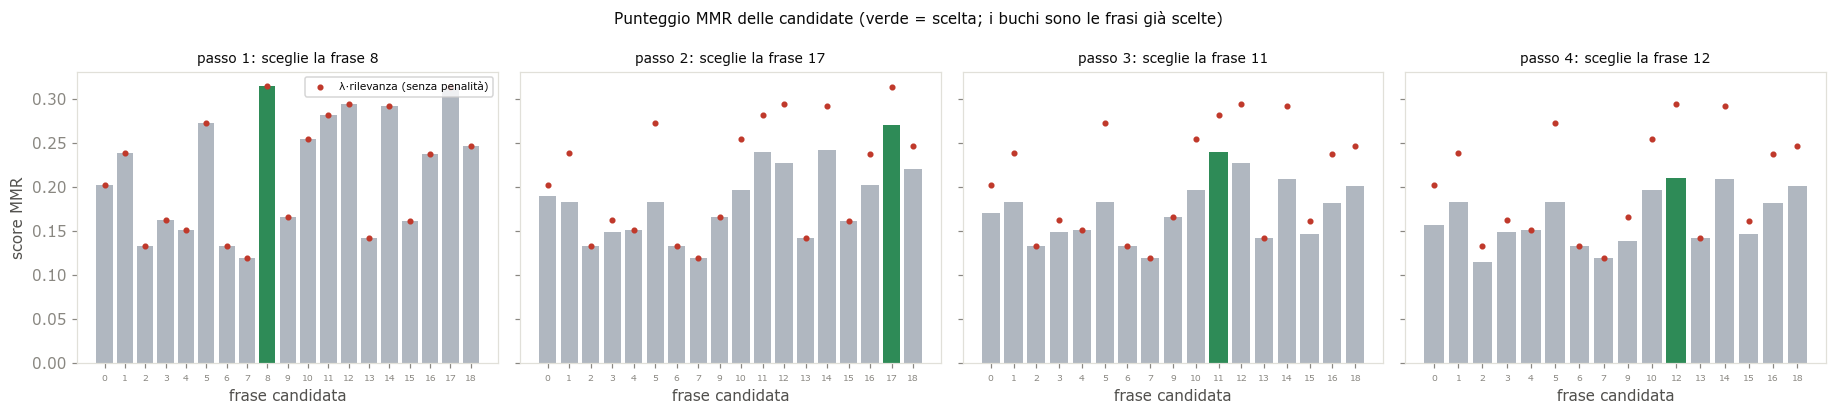

In [9]:
passi_mostrati = [0, 1, 2, 3] if len(storia_mmr) >= 4 else list(range(len(storia_mmr)))
fig, assi = plt.subplots(1, len(passi_mostrati), figsize=(4.2 * len(passi_mostrati), 3.8), sharey=True)
assi = np.atleast_1d(assi)
for ax, t in zip(assi, passi_mostrati):
    passo = storia_mmr[t]
    cand = sorted(passo['punteggi'])
    punt = [passo['punteggi'][i][0] for i in cand]
    cols = ['#2e8b57' if i == passo['scelto'] else ('#7f8c8d' if i in ordine_mmr[:t] else '#b0b7c0') for i in cand]
    ax.bar(range(len(cand)), punt, color=cols)
    ax.plot(range(len(cand)), [LAMBDA * passo['punteggi'][i][1] for i in cand], 'o', ms=3, color='#c0392b',
            label='λ·rilevanza (senza penalità)')
    ax.set_xticks(range(len(cand))); ax.set_xticklabels(cand, fontsize=6)
    ax.set_title(f"passo {t + 1}: sceglie la frase {passo['scelto']}", fontsize=9); ax.set_xlabel('frase candidata')
assi[0].set_ylabel('score MMR'); assi[0].legend(fontsize=7)
plt.suptitle('Punteggio MMR delle candidate (verde = scelta; i buchi sono le frasi già scelte)', fontsize=10)
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** Il punto rosso (la sola rilevanza pesata) è sempre ≥ della barra: la
differenza è la **penalità di ridondanza**. Le frasi già scelte spariscono dalle candidate, e col
procedere dei passi le barre si abbassano perché ci sono sempre più frasi "già dette" con cui
confrontarsi.

Verifichiamo ora che questa versione **coincida con l'implementazione del benchmark**. Qui sotto
`analizza_mmr` e `genera` sono copiate **identiche** dal notebook 11: se un giorno le due divergessero,
queste `assert` si romperebbero.

In [10]:
# --- copia fedele del codice di produzione (notebooks/11_centroid_mmr.ipynb) ---------------------
def analizza_mmr(frasi, vettorizza=vettorizza_tfidf, lam=None, k=None):
    lam = LAMBDA if lam is None else lam
    k = N_SENTENCES if k is None else k
    X = vettorizza(frasi)
    centroide = np.asarray(X.mean(axis=0)).reshape(1, -1)
    rilevanza = cosine_similarity(X, centroide).ravel()
    sim = cosine_similarity(X)
    scelti, candidati = [], list(range(len(frasi)))
    while len(scelti) < k and candidati:
        migliore, punteggio_migliore = None, -np.inf
        for i in candidati:
            ridondanza = max((sim[i][j] for j in scelti), default=0.0)
            punteggio = lam * rilevanza[i] - (1.0 - lam) * ridondanza
            if punteggio > punteggio_migliore:
                punteggio_migliore, migliore = punteggio, i
        scelti.append(migliore)
        candidati.remove(migliore)
    return {'X': X, 'centroide': centroide, 'rilevanza': rilevanza, 'sim': sim, 'scelti': scelti}

def genera_produzione(documento, vettorizza, budget=None):
    frasi = [f.strip() for f in getattr(psr.summarization(documento, stop_words=['en']), 'original', []) if f and f.strip()]
    if budget is None and len(frasi) <= N_SENTENCES:
        return ' '.join(frasi)
    k = N_SENTENCES if budget is None else min(len(frasi), K_ORDINE_BUDGET)
    try:
        ordine = analizza_mmr(frasi, vettorizza=vettorizza, k=k)['scelti']
    except ValueError:
        ordine = range(k)
    if budget is not None:
        ordine = su.seleziona_per_budget(frasi, ordine, budget)
    return ' '.join(frasi[i] for i in sorted(ordine))
# ---------------------------------------------------------------------------------------------------

prod = analizza_mmr(frasi, vettorizza=VETTORIZZATORI[VETTORIZZAZIONE], k=K_DEMO)
assert np.allclose(prod['rilevanza'], rilevanza) and np.allclose(prod['sim'], sim)
assert prod['scelti'] == ordine_mmr, 'il greedy scritto a mano deve coincidere con il benchmark'
print(f"✔ Rilevanza, matrice di similarità e ordine di selezione coincidono con analizza_mmr(): {ordine_mmr[:8]}…")

# il prefisso del greedy non dipende da k: fermarsi al passo t == tagliare l'ordine lungo (è ciò che rende valido il budget)
assert analizza_mmr(frasi, vettorizza=VETTORIZZATORI[VETTORIZZAZIONE], k=5)['scelti'] == ordine_mmr[:5]
print('✔ Le prime 5 scelte sono le stesse con k = 5 e con k più grande: tagliare l\'ordine = fermare il greedy.')

✔ Rilevanza, matrice di similarità e ordine di selezione coincidono con analizza_mmr(): [8, 17, 11, 12, 14, 10, 18, 5]…
✔ Le prime 5 scelte sono le stesse con k = 5 e con k più grande: tagliare l'ordine = fermare il greedy.


### Effetto di λ
`λ` è la manopola del metodo. La figura mostra **quali frasi entrano** nelle prime `N_SENTENCES`
posizioni al variare di λ (1,0 = pura rilevanza, valori più bassi = più diversità) e, sotto, la
**ridondanza media** del set scelto (similarità media tra tutte le coppie scelte): dovrebbe calare al
diminuire di λ — a costo di scegliere frasi meno centrali.

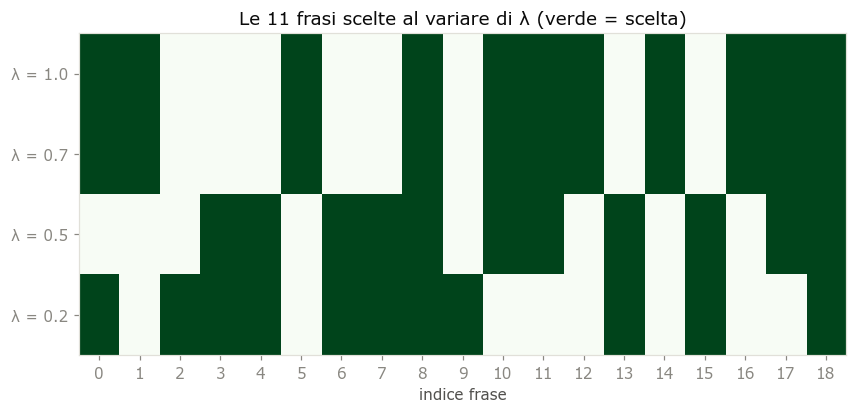

,ridondanza media del set,rilevanza media del set,frasi in comune con λ=1
λ = 1.0,0.109,0.383,11
λ = 0.7,0.109,0.383,11
λ = 0.5,0.030,0.296,5
λ = 0.2,0.011,0.251,3


In [11]:
LAMBDA_CONFRONTO = [1.0, 0.7, 0.5, 0.2]
K_L = min(N, N_SENTENCES)

def ridondanza_media(sim, indici):
    coppie_ = [sim[a][b] for i, a in enumerate(indici) for b in indici[i + 1:]]
    return float(np.mean(coppie_)) if coppie_ else 0.0

sel_lam = {lam: mmr_passo_passo(rilevanza, sim, lam, K_L)[0] for lam in LAMBDA_CONFRONTO}
M = np.zeros((len(LAMBDA_CONFRONTO), N))
for r, lam in enumerate(LAMBDA_CONFRONTO):
    M[r, sel_lam[lam]] = 1.0

fig, ax = plt.subplots(figsize=(9, 2.2 + 0.4 * len(LAMBDA_CONFRONTO)))
ax.imshow(M, cmap='Greens', vmin=0, vmax=1, aspect='auto')
ax.set_yticks(range(len(LAMBDA_CONFRONTO))); ax.set_yticklabels([f'λ = {lam}' for lam in LAMBDA_CONFRONTO])
ax.set_xticks(range(N)); ax.set_xlabel('indice frase')
ax.set_title(f'Le {K_L} frasi scelte al variare di λ (verde = scelta)')
plt.show()

tab = pd.DataFrame({
    'ridondanza media del set': [round(ridondanza_media(sim, sel_lam[lam]), 3) for lam in LAMBDA_CONFRONTO],
    'rilevanza media del set': [round(float(rilevanza[sel_lam[lam]].mean()), 3) for lam in LAMBDA_CONFRONTO],
    'frasi in comune con λ=1': [len(set(sel_lam[lam]) & set(sel_lam[1.0])) for lam in LAMBDA_CONFRONTO],
}, index=[f'λ = {lam}' for lam in LAMBDA_CONFRONTO])
display(tab)

**Cosa abbiamo visto.** Con `λ = 1` MMR coincide con il puro centroide (nessuna penalità). Abbassando λ
l'insieme scelto cambia, la **ridondanza media scende** e la rilevanza media scende con essa:
è il compromesso che λ regola. *Attenzione:* con il valore del benchmark (`λ = 0,7`) il **set** di 11 frasi
su 19 può risultare identico a quello di `λ = 1` — il greedy deve comunque riempire 11 posti su 19 e la
penalità, qui, è piccola (similarità basse tra frasi). Cambia però l'**ordine** di scelta (vedi la tabella
del passo per passo rispetto all'ordinamento per sola rilevanza della sezione 5), che conta quando ci si
ferma a un budget di parole. Le differenze sul set si vedono meglio con λ più bassa, con `N_SENTENCES`
piccolo o su cluster lunghi.

## 8. Selezione delle frasi
Il greedy produce un **ordine** (la sequenza `ordine_mmr`); poi la `MODALITA` decide dove fermarsi:

- **`'frasi'`**: si tengono le prime `N_SENTENCES = 11` scelte (11 è la mediana del numero di frasi dei
  riassunti del corpus). Se il documento ha già ≤ 11 frasi, si prendono tutte;
- **`'budget'`**: si accumulano frasi **nello stesso ordine** finché si raggiunge il **budget**
  = lunghezza in parole del riferimento (`su.seleziona_per_budget`: la frase che sfora viene
  inclusa solo se ne entra più della metà). Si usa solo la *lunghezza* del gold, mai il suo
  contenuto. Il benchmark calcola un ordine lungo fino a `K_ORDINE_BUDGET = 50` frasi e poi lo taglia: grazie
  alla proprietà del prefisso verificata sopra, è equivalente a fermare il greedy al budget.

In entrambi i casi l'ordine è lo stesso: cambia solo il punto di taglio.

MODALITA = 'budget': selezionate 4 frasi (154 parole) | budget = 168 parole


,frase,rilevanza,parole,scelta,testo
ordine del greedy,,,,,
1,8,0.450,37,✔,"Secondly, the removal of the Facebook John Snow Kiss-In event: \n \n It turns out …"
2,17,0.448,13,✔,The page used a photo of two men kissing to promote the event…
3,11,0.403,62,✔,Now if Facebook will only reply to Richard’s query about why they removed my ori…
4,12,0.420,42,✔,"Also, Richard did not state in his post that Facebook HAD taken the event page d…"
5,14,0.416,68,,"Here is a report on the John Snow Kiss-In from the Guardian, featuring an interv…"
6,10,0.363,61,,"Before it goes too far, I just want people to know that FB have NOT removed the …"
7,18,0.351,68,,"According to NYULocal.com, the photo was quickly removed and the following e-mai…"
8,5,0.389,25,,"In relation to the John Snow Kiss-In event, I used this particular photo because…"
9,16,0.339,25,,"We apologize for the inconvenience"" \n \n \n \n The Dangerous Minds Facebook page wa…"


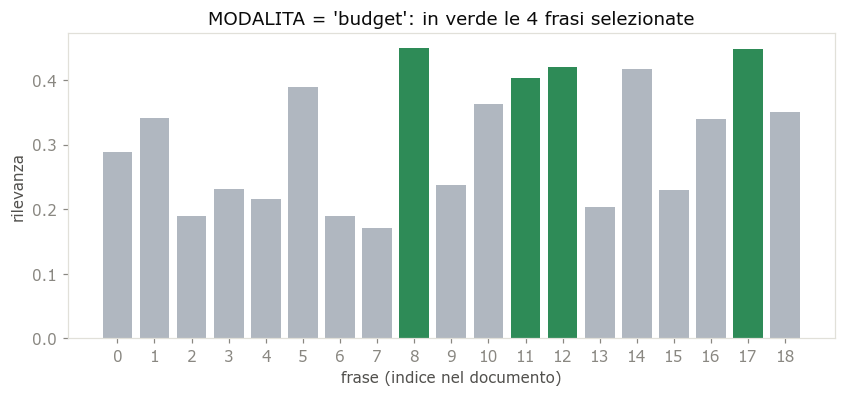

In [12]:
budget = su.budget_riferimento(esempio)                 # = parole del riferimento
idx_frasi = ordine_mmr[:N_SENTENCES]
idx_budget = su.seleziona_per_budget(frasi, ordine_mmr, budget)
idx_scelti = idx_frasi if MODALITA == 'frasi' else idx_budget
selezionate = set(idx_scelti)
print(f"MODALITA = '{MODALITA}': selezionate {len(idx_scelti)} frasi "
      f"({sum(len(frasi[i].split()) for i in idx_scelti)} parole) | budget = {budget} parole")

posizione_greedy = {i: t for t, i in enumerate(ordine_mmr, 1)}
classifica = pd.DataFrame({
    'ordine del greedy': range(1, len(ordine_mmr) + 1),
    'frase': ordine_mmr,
    'rilevanza': [round(float(rilevanza[i]), 3) for i in ordine_mmr],
    'parole': [len(frasi[i].split()) for i in ordine_mmr],
    'scelta': ['✔' if i in selezionate else '' for i in ordine_mmr],
    'testo': [frasi[i][:80] + '…' for i in ordine_mmr],
}).set_index('ordine del greedy')
display(classifica)

colori = ['#2e8b57' if i in selezionate else '#b0b7c0' for i in range(N)]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(N), rilevanza, color=colori)
ax.set_xticks(range(N)); ax.set_xlabel('frase (indice nel documento)'); ax.set_ylabel('rilevanza')
ax.set_title(f"MODALITA = '{MODALITA}': in verde le {len(selezionate)} frasi selezionate")
plt.show()

**Cosa abbiamo visto.** L'ordine del greedy **non coincide** con l'ordinamento per sola rilevanza
(confrontalo con la tabella della sezione 5): una frase meno rilevante ma *nuova* può passare davanti a una
più rilevante ma simile a una già scelta. Come per TextRank/LexRank, nessun criterio di *posizione* (come nel
baseline First-k). Nota anche che in modalità `'budget'` il numero di frasi può essere molto piccolo: su
questa riga le frasi sono lunghe e il budget ne contiene poche.

Qui sotto la vista PCA: le frasi proiettate in 2D, il centroide (stella) vicino al centro, colore =
rilevanza, bordo nero = frasi scelte.

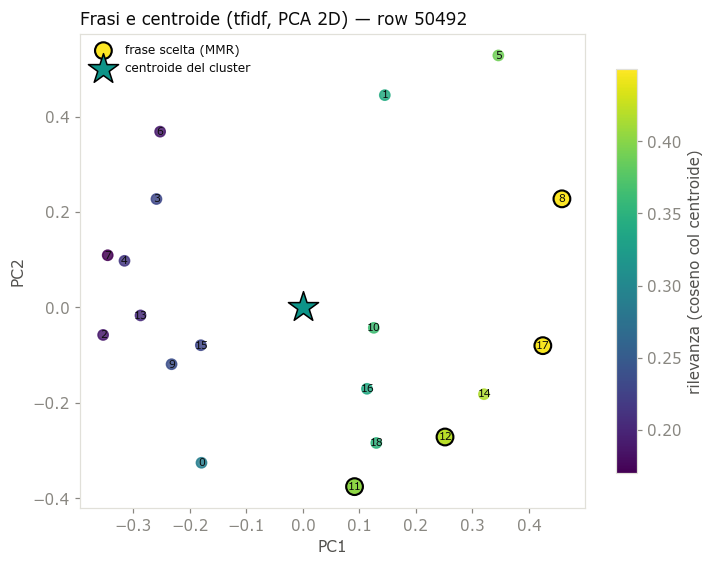

Varianza spiegata dalle 2 componenti: 15% (la proiezione è una semplificazione: le distanze in 2D sono approssimate).


In [13]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
XY = pca.fit_transform(Xd)
cxy = pca.transform(centroide)
m = np.zeros(N, dtype=bool); m[list(selezionate)] = True
norm = plt.Normalize(vmin=float(rilevanza.min()), vmax=float(rilevanza.max()))

fig, ax = plt.subplots(figsize=(7.4, 5.6))
ax.scatter(XY[~m, 0], XY[~m, 1], s=45, c=rilevanza[~m], cmap='viridis', norm=norm, alpha=0.85, zorder=2)
sc = ax.scatter(XY[m, 0], XY[m, 1], s=120, c=rilevanza[m], cmap='viridis', norm=norm, edgecolors='black', linewidths=1.4,
                label='frase scelta (MMR)', zorder=3)
ax.scatter(cxy[0, 0], cxy[0, 1], marker='*', s=430, c='#0d9488', edgecolors='black', linewidths=1.0,
           label='centroide del cluster', zorder=4)
for i in range(N):
    ax.annotate(str(i), (XY[i, 0], XY[i, 1]), fontsize=7, ha='center', va='center', zorder=5)
fig.colorbar(sc, ax=ax, shrink=0.85, label='rilevanza (coseno col centroide)')
ax.set_title(f'Frasi e centroide ({VETTORIZZAZIONE}, PCA 2D) — row {ROW_ID}', loc='left', fontsize=11)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(frameon=False, fontsize=8)
plt.show()
print(f'Varianza spiegata dalle 2 componenti: {pca.explained_variance_ratio_.sum():.0%} '
      '(la proiezione è una semplificazione: le distanze in 2D sono approssimate).')

## 9. Generazione del riassunto finale
Il riassunto è la concatenazione delle frasi **originali** scelte, **rimesse in ordine di documento**
(`sorted`): a differenza di TextRank/LexRank — che emettono per punteggio decrescente — Centroid+MMR
riordina secondo la posizione, quindi il testo segue l'ordine in cui le notizie compaiono negli
articoli. In modalità `'budget'` si applica poi il **tetto**: troncamento alle prime
`round(1,25 × lunghezza del riferimento)` parole (`su.tetto_riferimento`), come fa il benchmark prima di
calcolare le metriche. Verifichiamo che il testo coincida con quello di `genera()` del notebook 11.

In [14]:
tetto = su.tetto_riferimento(esempio)         # round(1,25 × riferimento)
vett_fn = VETTORIZZATORI[VETTORIZZAZIONE]

riassunto_frasi = ' '.join(frasi[i] for i in sorted(idx_frasi))
riassunto_budget = ' '.join(frasi[i] for i in sorted(idx_budget))
riassunto_budget_tetto = su.tronca_parole(riassunto_budget, tetto)

# verifica contro la funzione di produzione (stesso testo che finirebbe in results/summaries/)
assert riassunto_frasi == genera_produzione(documento, vett_fn)
assert riassunto_budget == genera_produzione(documento, vett_fn, budget=budget)
print("✔ 'frasi' e 'budget' coincidono con genera() del notebook 11")

riassunto = riassunto_frasi if MODALITA == 'frasi' else riassunto_budget_tetto   # ← quello che si valuta
if MODALITA == 'budget':
    print(f'  budget = {budget} parole | tetto = {tetto} parole | prima del tetto: {len(riassunto_budget.split())} parole')
print(f"\nRIASSUNTO — MODALITA '{MODALITA}' ({len(riassunto.split())} parole, ordine di documento):\n")
print(textwrap.fill(riassunto, 110))

✔ 'frasi' e 'budget' coincidono con genera() del notebook 11
  budget = 168 parole | tetto = 210 parole | prima del tetto: 154 parole

RIASSUNTO — MODALITA 'budget' (154 parole, ordine di documento):

Secondly, the removal of the Facebook John Snow Kiss-In event:     It turns out that the Facebook event for
the John Snow Kiss-In was not blocked by Facebook, but made private by the creator of the event itself Now if
Facebook will only reply to Richard’s query about why they removed my original post and photo when he put it
up on his wall…     It has been erroneously reported in the media that our own Richard Metzger (who lives in
Los Angeles) organized the London “Kiss-In” event, which is untrue, and also unfair to Paul Shetler and the
actual organizers Also, Richard did not state in his post that Facebook HAD taken the event page down, he just
questioned IF this was the case and IF there was a connection with MY post about the event being removed from
his own wall The page used a photo

**Cosa abbiamo visto.** Il riassunto è fatto di frasi copiate parola per parola, quindi può contenere
**riferimenti sospesi** ("he", "the company" senza antecedente) perché le frasi sono estratte dal loro
contesto. A differenza di TextRank/LexRank, la ridondanza è **controllata** (ma non eliminata: MMR
penalizza la similarità, non garantisce che due frasi dicano cose diverse). Infine il testo grezzo di
Multi-News contiene **rumore di scraping** (menu del sito, "Page 1 of 1", "UPDATE: …"): se una di
queste righe risulta rilevante, finisce nel riassunto.

## 10. Confronto con il riassunto di riferimento
Mettiamo a confronto il riassunto generato con quello umano e guardiamo le **lunghezze**
(la tabella mostra *entrambe* le modalità, la scelta è marcata da ◀): con 11 frasi fisse, Centroid+MMR
produce riassunti molto più lunghi del riferimento (nel benchmark: ~362 parole contro ~215). Questo è un
**confondente di lunghezza**: un riassunto più lungo ha più probabilità di contenere parole del
riferimento, e quindi *recall* più alta, indipendentemente dalla qualità della selezione.

Per questo il progetto ha introdotto la **rigenerazione a budget** (issue #16, protocollo
*length-matched*): il budget è la **lunghezza in parole del riferimento** (si usa solo la
*lunghezza* del gold, mai il suo contenuto). Si accumulano le frasi **nello stesso ordine del
greedy** finché si raggiunge il budget (`su.seleziona_per_budget`). Poi si applica il **tetto** a
1,25 × la lunghezza del riferimento (`su.tetto_riferimento`), troncando alle prime parole.

Qui confrontiamo le versioni già calcolate nella sezione 9.

In [15]:
marca = {'frasi': ' ◀' if MODALITA == 'frasi' else '', 'budget': ' ◀' if MODALITA == 'budget' else ''}
lung = pd.DataFrame({
    'parole': [len(riferimento.split()), len(riassunto_frasi.split()), len(riassunto_budget.split()), len(riassunto_budget_tetto.split())],
    'frasi': ['—', len(idx_frasi), len(idx_budget), len(idx_budget)],
}, index=['riferimento umano', 'generato — 11 frasi' + marca['frasi'], 'generato — budget (prima del tetto)',
          'generato — budget + tetto' + marca['budget']])
lung['rapporto col riferimento'] = (lung['parole'] / len(riferimento.split())).round(2)
display(lung)
print(f'budget = {budget} parole | tetto = {tetto} parole')

print('\n=== RIFERIMENTO UMANO ===');            print(textwrap.fill(riferimento, 110))
print(f"\n=== GENERATO — MODALITA '{MODALITA}' ===");  print(textwrap.fill(riassunto, 110))

,parole,frasi,rapporto col riferimento
riferimento umano,168,—,1.00
generato — 11 frasi,520,11,3.10
generato — budget (prima del tetto),154,4,0.92
generato — budget + tetto ◀,154,4,0.92


budget = 168 parole | tetto = 210 parole

=== RIFERIMENTO UMANO ===
It turns out Facebook is only guilty of about half of what it’s been accused of in the gay kiss incident. The
social networking site apologized yesterday for taking down an image used to promote a “kiss-in” event in
London. “The photo in question does not violate our Statement of Rights and Responsibilities, and was removed
in error,” the site said in a statement, according to the Advocate. But Facebook did not, as has been reported
in several places, take down the kiss-in event itself. Here’s what happened: The photo Facebook took down was
posted by the Dangerous Minds blog to promote the event. In its initial write-up about the incident, the blog
observed that the page organizing the protest had been taken down. But it was actually the organizer himself
who "removed" the event, Dangerous Minds clarified. Organizer Paul Shetler explains that he decided to switch
it from a public event to a private one, as "there were 

**Cosa abbiamo visto.** Il riassunto a 11 frasi è tipicamente **molto più lungo** del
riferimento; quello a budget ha una lunghezza paragonabile (la tabella mostra entrambi). Il riferimento,
inoltre, è *abstractive*: riformula, sintetizza e ordina le informazioni in modo che nessuna frase estratta
potrà mai riprodurre alla lettera. Questo pone un **limite superiore** alle metriche di sovrapposizione per
qualsiasi metodo estrattivo.

## 11. Calcolo delle metriche di valutazione
Le metriche misurano la **sovrapposizione** tra riassunto generato e riferimento (testo
normalizzato: minuscole, senza punteggiatura, **con** stopword e numeri). Sono quelle di
`pyAutoSummarizer`, identiche per tutti i metodi del benchmark:

| metrica | cosa misura |
|---|---|
| **ROUGE-1 / ROUGE-2** | sovrapposizione di unigrammi / bigrammi. **Precision** = quota degli n-grammi del generato presenti nel riferimento; **Recall** = quota degli n-grammi del riferimento ritrovati nel generato; **F1** = media armonica |
| **ROUGE-L** | sottosequenza comune più lunga (LCS), sensibile all'ordine delle parole |
| **BLEU** | precisione di n-grammi (1-4) con penalità di brevità |
| **METEOR** | corrispondenza di parole con penalità per la frammentazione dei match |

⚠️ **Caveat della libreria:** il ROUGE-N di `pyAutoSummarizer` usa **insiemi di n-grammi
unici** (non i conteggi *clipped* del ROUGE ufficiale): i valori sono confrontabili tra i metodi
di questo progetto ma **non** con quelli della letteratura.

Prima un calcolo di ROUGE-1 **a mano**, per vedere cosa c'è dentro i numeri.

In [16]:
valutatore = su.crea_valutatore()

def normalizza(testo):
    return valutatore.clear_text([testo], stop_words=[], lowercase=True, rmv_accents=False,
                                 rmv_special_chars=True, rmv_numbers=False, rmv_custom_words=[])[0].split()

def rouge1_a_mano(generato, rif):
    g, r = set(normalizza(generato)), set(normalizza(rif))     # insiemi di unigrammi UNICI
    comuni = g & r
    p, rec = len(comuni) / len(g), len(comuni) / len(r)
    return 2 * p * rec / (p + rec), p, rec, len(g), len(r), len(comuni)

f1, p, rec, ng, nr, nc = rouge1_a_mano(riassunto, riferimento)
print(f"Generato (MODALITA '{MODALITA}'): {ng} parole distinte | riferimento: {nr} parole distinte | in comune: {nc}")
print(f'precision = {nc}/{ng} = {p:.3f} | recall = {nc}/{nr} = {rec:.3f} | F1 = {f1:.3f}')

r1 = valutatore.rouge_N(riassunto, riferimento, n=1)          # (f1, precision, recall)
assert np.allclose([f1, p, rec], r1)
print('✔ Coincide con valutatore.rouge_N(…, n=1)')

Generato (MODALITA 'budget'): 93 parole distinte | riferimento: 103 parole distinte | in comune: 45
precision = 45/93 = 0.484 | recall = 45/103 = 0.437 | F1 = 0.459
✔ Coincide con valutatore.rouge_N(…, n=1)


Ora tutte le metriche, per il riassunto a **11 frasi** e per quello **a budget + tetto**
(le metriche dell'ambito `test_budgetref` del benchmark sono calcolate proprio sul testo dopo
il tetto). La colonna della modalità scelta è marcata da ◀; l'altra è lì per confronto.

,11 frasi,budget + tetto ◀
ROUGE-1 F1,0.381,0.459
ROUGE-1 precision,0.269,0.484
ROUGE-1 recall,0.650,0.437
ROUGE-2 F1,0.144,0.110
ROUGE-2 precision,0.097,0.116
ROUGE-2 recall,0.278,0.105
ROUGE-L F1,0.145,0.201
ROUGE-L precision,0.096,0.210
ROUGE-L recall,0.298,0.193
BLEU,0.066,0.057


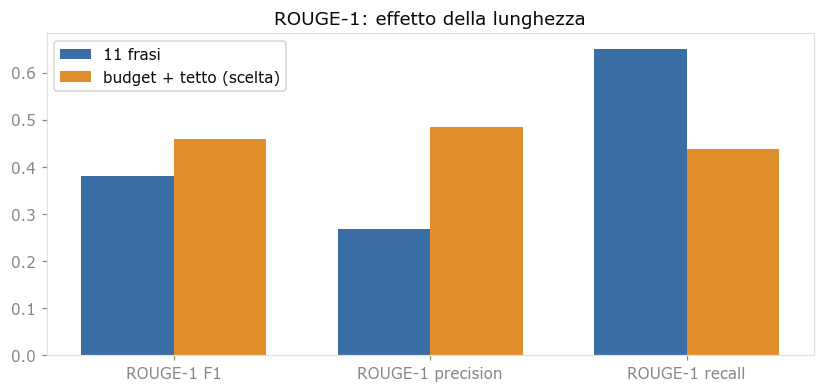

In [17]:
m11 = su.metriche_esempio(valutatore, riassunto_frasi, riferimento)
mbu = su.metriche_esempio(valutatore, riassunto_budget_tetto, riferimento)
m_scelta, m_altra = (m11, mbu) if MODALITA == 'frasi' else (mbu, m11)
assert np.isclose(m_scelta['rouge1_f1'], r1[0])   # coerente con il ROUGE-1 a mano della modalità scelta
et11 = '11 frasi' + (' ◀' if MODALITA == 'frasi' else '')
etbu = 'budget + tetto' + (' ◀' if MODALITA == 'budget' else '')

ordine_col = ['rouge1_f1', 'rouge1_p', 'rouge1_r', 'rouge2_f1', 'rouge2_p', 'rouge2_r',
              'rougeL_f1', 'rougeL_p', 'rougeL_r', 'bleu', 'meteor', 'parole_generate']
tab_metriche = pd.DataFrame({et11: m11, etbu: mbu}).loc[ordine_col]
tab_metriche.index = ['ROUGE-1 F1', 'ROUGE-1 precision', 'ROUGE-1 recall', 'ROUGE-2 F1', 'ROUGE-2 precision', 'ROUGE-2 recall',
                      'ROUGE-L F1', 'ROUGE-L precision', 'ROUGE-L recall', 'BLEU', 'METEOR', 'parole generate']
display(tab_metriche.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
chiavi = ['rouge1_f1', 'rouge1_p', 'rouge1_r']
x = np.arange(len(chiavi)); w = .36
ax.bar(x - w / 2, [m11[k] for k in chiavi], w, label=et11.replace(' ◀', ' (scelta)'), color='#3b6ea5')
ax.bar(x + w / 2, [mbu[k] for k in chiavi], w, label=etbu.replace(' ◀', ' (scelta)'), color='#e08e2b')
ax.set_xticks(x); ax.set_xticklabels(['ROUGE-1 F1', 'ROUGE-1 precision', 'ROUGE-1 recall'])
ax.legend(); ax.set_title('ROUGE-1: effetto della lunghezza')
plt.show()

**Cosa abbiamo visto.** Con più parole la **recall** sale (si "pescano" più parole del
riferimento) ma la **precision** scende (molte parole in più non servono): la **F1** compensa i
due effetti ed è la metrica più onesta quando le lunghezze sono diverse. A parità di lunghezza
(budget), la differenza tra metodi riflette davvero la qualità della *selezione dei contenuti*.

## 12. Interpretazione dei risultati
Il commento seguente legge i numeri **di questa riga** (si aggiorna se cambi `ROW_ID`).

In [18]:
nome_altra = 'budget + tetto' if MODALITA == 'frasi' else '11 frasi'
dr, db = m_altra['rouge1_r'] - m_scelta['rouge1_r'], m_altra['rouge1_p'] - m_scelta['rouge1_p']
testo = f'''
**Riga {ROW_ID} — Centroid+MMR ({VETTORIZZAZIONE}, λ = {LAMBDA}) — MODALITA `'{MODALITA}'`.**

- Il riassunto ha {m_scelta['parole_generate']} parole contro le {len(riferimento.split())} del riferimento
  ({m_scelta['parole_generate'] / len(riferimento.split()):.1f}×): ROUGE-1 recall = **{m_scelta['rouge1_r']:.3f}**,
  precision = **{m_scelta['rouge1_p']:.3f}**, F1 = **{m_scelta['rouge1_f1']:.3f}**.
- Per confronto, con la modalità *{nome_altra}* ({m_altra['parole_generate']} parole) la recall {'sale' if dr > 0 else 'scende'} a
  **{m_altra['rouge1_r']:.3f}** (Δ = {dr:+.3f}) e la precision {'sale' if db > 0 else 'scende'} a **{m_altra['rouge1_p']:.3f}**
  (Δ = {db:+.3f}): F1 = **{m_altra['rouge1_f1']:.3f}**.
- ROUGE-2 F1 = {m_scelta['rouge2_f1']:.3f} (modalità scelta): molto più bassa di ROUGE-1, perché le sequenze di **due parole**
  consecutive in comune col riferimento *astratto* sono rare — è tipico dei metodi estrattivi.
'''
display(Markdown(testo))


**Riga 50492 — Centroid+MMR (tfidf, λ = 0.7) — MODALITA `'budget'`.**

- Il riassunto ha 154 parole contro le 168 del riferimento
  (0.9×): ROUGE-1 recall = **0.437**,
  precision = **0.484**, F1 = **0.459**.
- Per confronto, con la modalità *11 frasi* (520 parole) la recall sale a
  **0.650** (Δ = +0.214) e la precision scende a **0.269**
  (Δ = -0.215): F1 = **0.381**.
- ROUGE-2 F1 = 0.110 (modalità scelta): molto più bassa di ROUGE-1, perché le sequenze di **due parole**
  consecutive in comune col riferimento *astratto* sono rare — è tipico dei metodi estrattivi.


### Cosa portarsi a casa
1. **Centroid+MMR è un ordinamento di frasi con memoria.** Il centroide dà la *rilevanza* (indipendente
   dalle altre scelte); MMR la corregge con la *novità* rispetto a ciò che il riassunto già contiene. Lunghezza,
   ordine di emissione e coerenza del testo finale sono scelte esterne.
2. **λ è il compromesso salienza/diversità.** `λ = 1` è il puro centroide; abbassandolo la ridondanza del
   set cala, ma si rinuncia a frasi molto centrali. Nel benchmark `λ = 0,7` è fissato, non ottimizzato.
3. **Il risultato dipende dallo spazio dei vettori.** Con TF-IDF centroide e similarità sono lessicali
   (veloce, nessun modello, nessuna parafrasi); con BERT sono semantici (sezione 13).
4. **Un centroide solo.** Non c'è clustering a più temi: in un cluster che copre più sotto-argomenti, la media li
   sfuma. MMR compensa solo in parte.
5. **La lunghezza è un confondente.** Nel benchmark a 5.588 righe di test, `centroid_mmr`: ROUGE-1 F1
   0,383 (11 frasi, ~362 parole) → 0,378 (budget, ~215 parole); `centroid_mmr_bert`: 0,373 → 0,364. Il calo
   è piccolo ma ora è un confronto alla pari.
6. **Il tetto delle metriche estrattive.** Il riferimento è astratto; le frasi estratte non lo riprodurranno mai.

### Esercizi proposti
- Cambia `ROW_ID` (es. 50501, 50523) e osserva come cambiano heatmap, rilevanza e selezione.
- Passa `MODALITA` da `'frasi'` a `'budget'` (sezione 1) e rileggi le sezioni 8-12. Poi, con `'frasi'`, prova
  `N_SENTENCES = 5` e `3`: come si muovono precision, recall e F1?
- Imposta `LAMBDA = 1.0`, poi `0.3`: la ridondanza del set (sezione 7) cala? Le metriche migliorano o peggiorano?
- Imposta `VETTORIZZAZIONE = 'bert'` e rilancia: cambiano le coppie ridondanti nella heatmap? E le frasi scelte?

## 13. (Extra) TF-IDF e BERT a confronto sulla stessa riga
Le due varianti del benchmark (`centroid_mmr` e `centroid_mmr_bert`) differiscono **solo** per lo spazio dei
vettori; centroide, rilevanza, matrice di similarità e greedy sono identici. Calcoliamo qui entrambe sulla
stessa riga, con lo stesso `λ` e lo stesso criterio di lunghezza, e vediamo quanto si somigliano:
sovrapposizione delle frasi scelte, correlazione di Spearman delle rilevanze, metriche.

*La prima esecuzione scarica `all-MiniLM-L6-v2` (~90 MB).*

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2582.45it/s]

Frasi scelte da entrambe: 2 (solo TF-IDF: [8, 12] | solo BERT: [0])
Correlazione di Spearman tra le rilevanze: 0.74
Similarità media tra le frasi — TF-IDF: 0.05 | BERT: 0.30


,TF-IDF,BERT
rouge1_f1,0.459,0.369
rouge1_p,0.484,0.369
rouge1_r,0.437,0.369
rouge2_f1,0.110,0.082
rougeL_f1,0.201,0.142
meteor,0.507,0.369
parole_generate,154.000,135.000


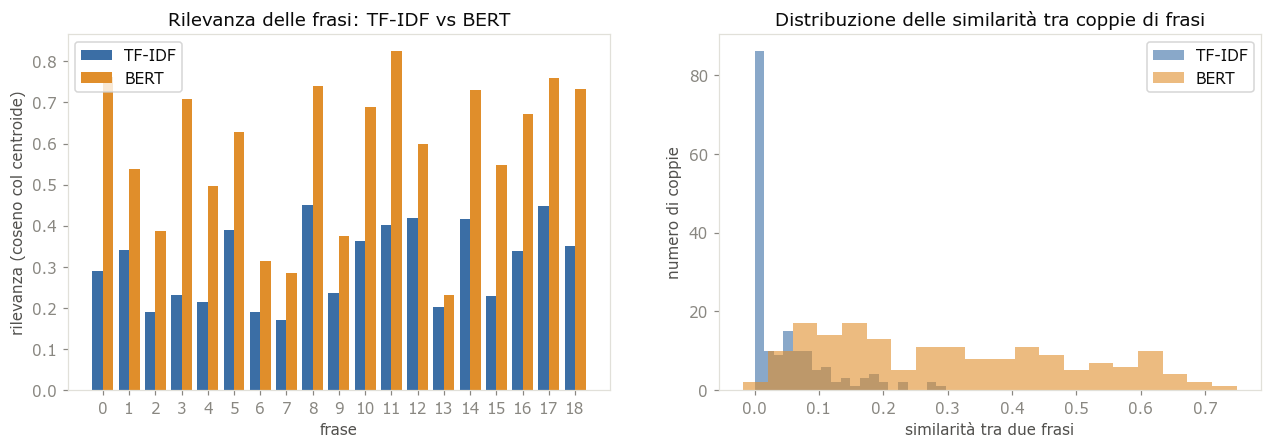

In [19]:
from scipy.stats import spearmanr

risultati = {}
for nome, f_vett in VETTORIZZATORI.items():
    art = analizza_mmr(frasi, vettorizza=f_vett, k=min(N, K_ORDINE_BUDGET))
    ordine = art['scelti']
    sel = ordine[:N_SENTENCES] if MODALITA == 'frasi' else su.seleziona_per_budget(frasi, ordine, budget)
    testo_ = ' '.join(frasi[i] for i in sorted(sel))
    if MODALITA == 'budget':
        testo_ = su.tronca_parole(testo_, tetto)
    risultati[nome] = {'art': art, 'sel': set(sel), 'testo': testo_,
                       'metriche': su.metriche_esempio(valutatore, testo_, riferimento)}

a, b = risultati['tfidf'], risultati['bert']
rho = spearmanr(a['art']['rilevanza'], b['art']['rilevanza']).statistic
print(f"Frasi scelte da entrambe: {len(a['sel'] & b['sel'])} (solo TF-IDF: {sorted(a['sel'] - b['sel'])} | solo BERT: {sorted(b['sel'] - a['sel'])})")
print(f"Correlazione di Spearman tra le rilevanze: {rho:.2f}")
print(f"Similarità media tra le frasi — TF-IDF: {a['art']['sim'][coppie].mean():.2f} | BERT: {b['art']['sim'][coppie].mean():.2f}")

display(pd.DataFrame({
    f'TF-IDF': {k: a['metriche'][k] for k in ('rouge1_f1', 'rouge1_p', 'rouge1_r', 'rouge2_f1', 'rougeL_f1', 'meteor', 'parole_generate')},
    f'BERT':   {k: b['metriche'][k] for k in ('rouge1_f1', 'rouge1_p', 'rouge1_r', 'rouge2_f1', 'rougeL_f1', 'meteor', 'parole_generate')},
}).round(3))

fig, assi = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(N); w = .4
assi[0].bar(x - w / 2, a['art']['rilevanza'], w, label='TF-IDF', color='#3b6ea5')
assi[0].bar(x + w / 2, b['art']['rilevanza'], w, label='BERT', color='#e08e2b')
assi[0].set_xticks(x); assi[0].set_xlabel('frase'); assi[0].set_ylabel('rilevanza (coseno col centroide)'); assi[0].legend()
assi[0].set_title('Rilevanza delle frasi: TF-IDF vs BERT')
for nome, ax_, colore in (('tfidf', assi[1], '#3b6ea5'), ('bert', assi[1], '#e08e2b')):
    v = risultati[nome]['art']['sim'][coppie]
    ax_.hist(v, bins=20, alpha=.6, color=colore, label={'tfidf': 'TF-IDF', 'bert': 'BERT'}[nome])
assi[1].set_xlabel('similarità tra due frasi'); assi[1].set_ylabel('numero di coppie'); assi[1].legend()
assi[1].set_title('Distribuzione delle similarità tra coppie di frasi')
plt.show()

**Cosa abbiamo visto.** Gli embedding BERT danno similarità mediamente **più alte e meno separate**
(anche frasi lessicalmente diverse hanno un coseno positivo perché parlano dello stesso evento), mentre TF-IDF
è nettamente più "a scalini" (molte coppie a 0). Le due rilevanze sono correlate ma non identiche, e le frasi scelte
si sovrappongono solo in parte. Nel benchmark la differenza di qualità è piccola e va **a favore del TF-IDF**
(ROUGE-1 F1 0,383 vs 0,373 con 11 frasi; 0,378 vs 0,364 a budget): rappresentare il *significato* non basta a
battere il puro lessico quando il riferimento è fatto in gran parte delle stesse parole degli articoli.